# Introducción
## Objetivo
El proyecto consta de hacer un detector de objetos que incumplan estándares de vestimenta en un departamento de pintura para Ford Motor Company.  

El objetivo es impedir daños a la pintura de los vehículos en las líneas de ensamblaje, por lo que detectar e ilustrar la detección en video permite retroalimentar al personal con lo que debe de corregir.

## Unidad de análisis
Tras capturar imágenes de personal con diferentes niveles de cumplimiento se generó un .csv con datos de las coordenadas de los artículos que porta el personal que incumplen.  Derivado del mismo .csv se extrajeron muestras de los objetos y se almacenaron:  
* Imagenes originales:  Se encuentran almacenadas en _DataCapture/Raw_, tienen el rostro cubierto desde la adquisición por medio de código en OpenCV donde debe cumplirse la detección y sombreo de la cara para generar la captura
* Objetos con potencial de generar daño:  Se encuentran almacenados en la carpeta _DataCapture/NG_, dichas muestras serán de utilidad para entrenar un modelo con la capacidad de encontrarlos.
* Base de datos:  Es un csv localizado tambien en _DataCapture/anotaciones.csv_.  

En general el folder DataCapture está formulado para generar datos capturando sin rostro y con una libreta y pedazos de código capaces de permitir el rodeado de objetos por medio de una persona.  Dicho ésto el objetivo es tener datos etiquetados para un posterior *aprendizaje supervisado*.  

## Operaciones futuras
El uso de los scripts permitirá aumentar las muestras en un futuro para asegurar reentrenamiento

# Estructura de los datos
## Inventario y esquema
Al momento se lograron generar 41 imagenes con un total de 68 items identificados como potencial generador de daños a la pintura. 

| Datos        | Cantidad     | Formato
|--------------|--------------|----------|
| Imagenes Originales | 41 | .jpg  |
| Objetos Recortados  | 68 | .jpg  |
| Base de anotaciones | 1 | .csv |



In [10]:
## Conteo actualizado de imágenes y anotaciones
from pathlib import Path
import pandas as pd

#EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
EXTENSIONS = {".jpg"}
RAW_DIR = Path("../DataCapture/raw")
ObjectDir = Path("../DataCapture/NG")

for ext in EXTENSIONS:
    raw_files = list(RAW_DIR.glob(f"*{ext}"))
    print(f"Se encontraron {len(raw_files)} imágenes {ext}.")

for ext in EXTENSIONS:
    object_files = list(ObjectDir.glob(f"*{ext}"))
    print(f"Se encontraron {len(object_files)} objetos {ext}.")

df = pd.read_csv("../DataCapture/anotaciones.csv")
print(f"Se encontraron {len(df)} anotaciones en el archivo CSV.")


Se encontraron 41 imágenes .jpg.
Se encontraron 68 objetos .jpg.
Se encontraron 114 anotaciones en el archivo CSV.


## Calidad e integridad  
Al momento se hizo depuración manual de las imagenes ya que se encontraron un total de 20 imágenes desenfocadas con donde se estaban borrando objetos clave.

In [35]:
## Detectando imágenes sin anotaciones
# Obtener la lista de imágenes anotadas
df_dropna = df.dropna(subset=["x", "y"])
#df_dropna.groupby("imagen").size().reset_index(name="count")

print("Imágenes con anotaciones:")
df_dropna.groupby("imagen").size().reset_index(name="count")
#df_dropna.groupby("imagen").reset_index(name="count")

Imágenes con anotaciones:


,imagen,count
0,captura_20261003_153016_534962.jpg,1
1,captura_20261003_153021_540685.jpg,1
2,captura_20261003_153051_624221.jpg,1
3,captura_20261003_153056_648946.jpg,1
4,captura_20261003_153101_657504.jpg,1
5,captura_20261003_153838_135146.jpg,2
6,captura_20261003_153944_399966.jpg,2
7,captura_20261003_153949_427154.jpg,2
8,captura_20261003_153954_440259.jpg,3
9,captura_20261003_154213_767364.jpg,5


# Análisis univariante

TBD:  Ancho, alto, proporción, tamaño de archivo; histogramas de capturas

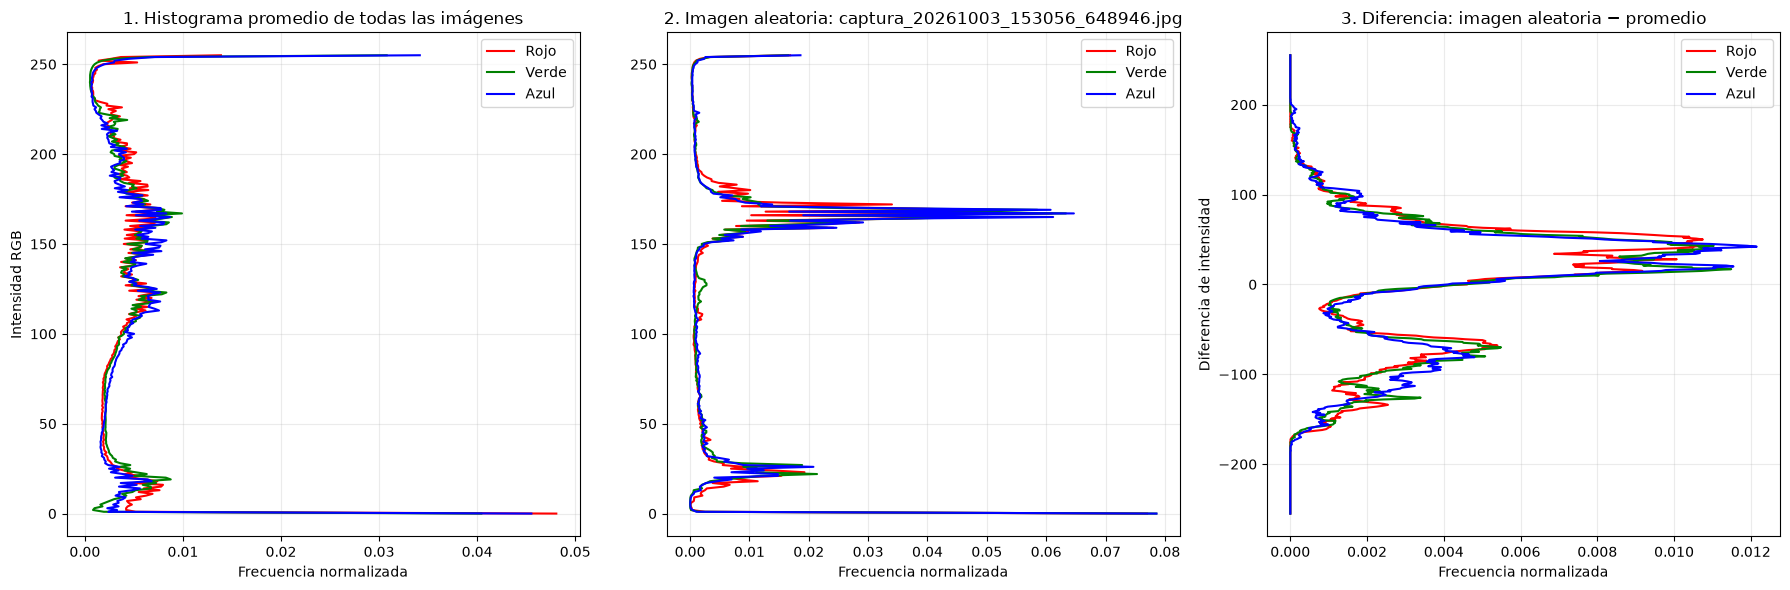

In [38]:
from PIL import Image
import numpy as np

import matplotlib.pyplot as plt

# Igualar dimensiones para poder calcular la imagen promedio píxel a píxel.
# Se usa la resolución de la primera imagen como referencia.
image_paths = sorted(RAW_DIR.glob("*.jpg"))
if not image_paths:
    raise FileNotFoundError(f"No se encontraron imágenes en {RAW_DIR}")

with Image.open(image_paths[0]) as first_image:
    target_size = first_image.size

images_rgb = []
for path in image_paths:
    with Image.open(path) as image:
        image = image.convert("RGB").resize(target_size)
        images_rgb.append(np.asarray(image, dtype=np.float32))

# Elige una imagen aleatoria reproducible y calcula el promedio píxel a píxel.
rng = np.random.default_rng(42)
sample_index = rng.integers(len(images_rgb))
sample_image = images_rgb[sample_index]
mean_image = np.mean(images_rgb, axis=0)
difference = sample_image - mean_image

channel_colors = ["red", "green", "blue"]
channel_names = ["Rojo", "Verde", "Azul"]

# Histogramas normalizados; se grafican horizontalmente (intensidad en el eje Y).
average_histograms = []
for channel in range(3):
    per_image = [
        np.histogram(image[:, :, channel], bins=256, range=(0, 256), density=True)[0]
        for image in images_rgb
    ]
    average_histograms.append(np.mean(per_image, axis=0))

sample_histograms = [
    np.histogram(sample_image[:, :, c], bins=256, range=(0, 256), density=True)[0]
    for c in range(3)
]

difference_bins = np.arange(-255.5, 256.5, 1)
difference_histograms = [
    np.histogram(difference[:, :, c], bins=difference_bins, density=True)[0]
    for c in range(3)
]
difference_centers = (difference_bins[:-1] + difference_bins[1:]) / 2

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=False)

for c, color in enumerate(channel_colors):
    axes[0].plot(average_histograms[c], np.arange(256), color=color, label=channel_names[c])
    axes[1].plot(sample_histograms[c], np.arange(256), color=color, label=channel_names[c])
    axes[2].plot(
        difference_histograms[c], difference_centers, color=color, label=channel_names[c]
    )

axes[0].set_title("1. Histograma promedio de todas las imágenes")
axes[0].set_ylabel("Intensidad RGB")
axes[1].set_title(f"2. Imagen aleatoria: {image_paths[sample_index].name}")
axes[2].set_title("3. Diferencia: imagen aleatoria − promedio")
axes[2].set_ylabel("Diferencia de intensidad")

for ax in axes:
    ax.set_xlabel("Frecuencia normalizada")
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

Utilizando el principio de "normalidad" se buscaron imagenes fuera de lugar o muy diferentes al resto.

,imagen,Diferencia promedio Rojo,Diferencia promedio Verde,Diferencia promedio Azul,Distancia euclideana
0,captura_20261003_153944_399966.jpg,0.005135,0.005132,0.005392,0.500220
1,captura_20261003_155238_738227.jpg,0.001927,0.002084,0.002356,0.268741
2,captura_20261003_153954_440259.jpg,0.002791,0.002800,0.003046,0.225955
3,captura_20261003_153056_648946.jpg,0.003494,0.003522,0.003754,0.205087
4,captura_20261003_153101_657504.jpg,0.003467,0.003447,0.003779,0.195108
5,captura_20261003_153949_427154.jpg,0.002023,0.002075,0.002396,0.189356
6,captura_20261003_153016_534962.jpg,0.003278,0.003621,0.003560,0.188025
7,captura_20261003_154700_253089.jpg,0.002425,0.002319,0.002716,0.179060
8,captura_20261003_153051_624221.jpg,0.003142,0.003097,0.003405,0.172774
9,captura_20261003_153021_540685.jpg,0.002673,0.002558,0.002453,0.140667


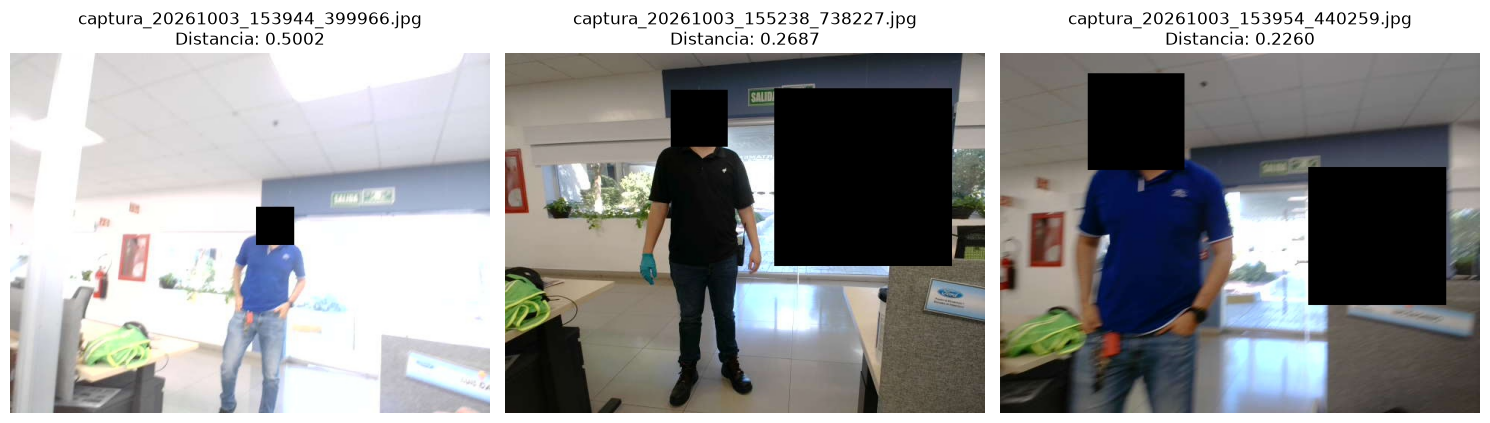

In [39]:
channel_names = ["Rojo", "Verde", "Azul"]
rows = []

for path, image_array in zip(image_paths, images_rgb):
    channel_differences = []

    for channel in range(3):
        image_histogram = np.histogram(
            image_array[:, :, channel],
            bins=256,
            range=(0, 256),
            density=True
        )[0]

        channel_differences.append(
            image_histogram - average_histograms[channel]
        )

    row = {"imagen": path.name}

    for channel, channel_name in enumerate(channel_names):
        row[f"Diferencia promedio {channel_name}"] = np.mean(
            np.abs(channel_differences[channel])
        )

    # Distancia euclideana sobre los 3 canales y todos los bins.
    row["Distancia euclideana"] = np.sqrt(
        sum(np.sum(diff ** 2) for diff in channel_differences)
    )
    rows.append(row)

df_diferencias_histograma = pd.DataFrame(rows).sort_values(
    "Distancia euclideana", ascending=False
).reset_index(drop=True)

display(df_diferencias_histograma)

# Mostrar las tres imágenes con mayor distancia al histograma promedio.
top3 = df_diferencias_histograma.head(3)
fig, axes = plt.subplots(1, len(top3), figsize=(15, 5))

for ax, (_, row) in zip(axes, top3.iterrows()):
    index = next(i for i, path in enumerate(image_paths) if path.name == row["imagen"])
    ax.imshow(images_rgb[index].astype(np.uint8))
    ax.set_title(f'{row["imagen"]}\nDistancia: {row["Distancia euclideana"]:.4f}')
    ax.axis("off")

plt.tight_layout()
plt.show()

Se observa que las 3 imagenes son significativamente diferentes:
1. Altamente iluminada por ajuste de sensibilidad del lente
2. Posee un cuadrado negro generado por el haarcasdade
3. Similar al anterior, posee un cuadrado negro que mueve al histograma

<Axes: title={'center': 'Histograma de distancias euclideanas al histograma promedio'}, ylabel='Frequency'>

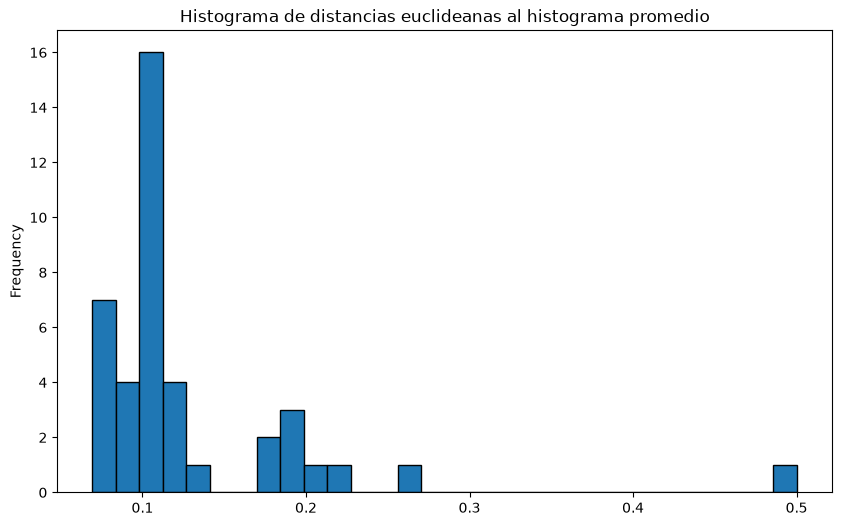

In [42]:
plt.title("Histograma de distancias euclideanas al histograma promedio")
df_diferencias_histograma["Distancia euclideana"].plot(kind="hist", bins=30, edgecolor="black", figsize=(10, 6))

Se determina que tales imágenes son anomalías, siendo solo la primera susceptible a eliminación por su diferencia significativa en la captura de iluminación.

# Análisis bi/multivariante

# Procesamiento
Por el momento el procesamiento al que se han sometido las muestras han sido para protección de datos de identificación personal.  
Etapas posteriores buscarán mantener estandarizado el espacio de prueba, el fondo y si es posible la iluminación.  
Si hay complicaciones futuras se buscaría tambien eliminar esas imágenes que tengan recuadros negros de "falso positivo"

# Conclusiones
Un proyecto de visión artificial enfocado a inspeccionar al personal requiere algunos enfoques peculiares:
## PII
Grabar a gente en general requiere de tomar consideraciones y protecciones adicionales ya que existe el riesgo de incurrir en problemas de ciberseguridad al exponer las llamadas PII (personal identificación information).  
Para efectos del proyecto se hizo un preprocesamiento que garantice que los rostros no sean visibles para un desarrollador externo.  Para la ejecución se debe hacer de manera local y sin enviar datos a través de internet, mientras que los controles establecidos para desarrollo del entrenamiento obligan a ocultar los rostros de las personas a pesar de tener su consentimiento.

## Ejecución
La ejecución debe ser offline y anonima.  El sistema de cubrimiento de rostros sigue vigente en la ejecución y solo se encargará de almacenar datos de detección ya que la principal función es *alertar al personal sobre lo que debe de corregir en su uniforme*. 

## Datos como imágenes

El proyecto de inspección visual requiere un enfoque donde los datos generados pueden actualizarse del mismo entorno de pruebas o producción.  Así mismo al no ser inherentemente un dato numéricos, sino un espacio 2D o una matriz donde es más importante una serie de relaciones espaciales que el de un valor, obtener datos descriptivos puede resultar abstracto.  *Un detector de imágenes anomalas* podría ser clave para una prediscriminación de imágenes que hayan sido capturadas bajo condiciones muy inusuales.  Tal enfoque permitiría conseguir datos de utilidad para una IA.